# Analysis


In [1]:
from pathlib import Path
rootDir = Path.cwd()

In [ ]:
# --- Parameters ---
INPUT_CSV = f"{rootDir}/Result/FirstDSdeepseekWithPrompt.csv"
OUTPUT_CSV = f"{rootDir}/Result/Exercise_with_complexity.csv"



In [ ]:
#Complexity Analysis (Formula (1))
import pandas as pd
import nltk
from nltk.corpus import stopwords
import string


nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')




# --- Helper functions ---
def compute_complexity(text):
    # Tokenize into sentences and words
    sentences = nltk.sent_tokenize(text)
    words = nltk.word_tokenize(text)

    # Basic counts
    NoS = len(sentences)
    NoW = len([w for w in words if w.isalnum()])  # exclude punctuation
    NoSW = len([w for w in words if w.lower() not in stopwords.words('english') and w.isalnum()])
    NoUW = len(set([w.lower() for w in words if w.isalnum()]))

    # Equation (1)
    complexity = ((0.4 * NoS) + (0.2 * NoW) + (0.2 * NoUW) + (0.2 * NoSW)) / 10

    if complexity < 5:
        label = "simple"
    elif complexity < 9:
        label = "medium"
    else:
        label = "complex"

    return pd.Series([NoS, NoW, NoSW, NoUW, complexity, label])

# --- Main ---
df = pd.read_csv(INPUT_CSV)

# Compute metrics for each prompt
df[['NoS', 'NoW', 'NoSW', 'NoUW', 'Complexity', 'Label']] = df['prompt'].apply(compute_complexity)

# Save results
df.to_csv(OUTPUT_CSV, index=False)
print(f"Complexity computed and saved to {OUTPUT_CSV}")
print(df.head())


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Complexity computed and saved to /content/drive/MyDrive/Paper3/HallucinationTaxonomy/Data/Exercise_with_complexity.csv
   Num                                             prompt  \
0    1  Project Management System\nA project manager u...   
1    2  Hollywood Approach\nWe are interested in build...   
2    3  Word Processor\nA user can open a new or exist...   
3    4  Patient Record and Scheduling System\nA patien...   
4    5  Movie-Shop\n Design a system for a movie-shop,...   

                                     deepseek_output  NoS  NoW  NoSW  NoUW  \
0  <think>\nWe are going to design a UML Class Di...   10  172   100    87   
1  <think>\nWe are going to create a UML class di...   10  206   109    90   
2  <think>\nWe are going to design a UML class di...    9  111    61    60   
3  <think>\nWe are going to model a Patient Recor...   12  178   105    86   
4  <think>\nWe are designing a system for a Movie...    5   71    34    49   

   Complexity   Label  
0        7.58  medium

In [ ]:
#Reasoning Length Analysis
import re

def extract_think_segment(text):
    text = str(text)
    start_match = re.search(r"<think>", text)
    end_match = re.search(r"</think>", text)

    if start_match and end_match:
        reasoning = text[start_match.end():end_match.start()]
    elif start_match and not end_match:
        reasoning = text[start_match.end():]
    else:
        reasoning = text

    return reasoning.strip()


df['reasoning'] = df['deepseek_output'].apply(extract_think_segment)
#df['reasoning'] = df['response'].apply(extract_think_segment)


In [ ]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained("deepseek-ai/deepseek-coder-6.7b-base")  # public model

df['thought_tokens'] = df['reasoning'].apply(lambda x: len(tokenizer.encode(x, add_special_tokens=False)))


config.json:   0%|          | 0.00/632 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/793 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.37M [00:00<?, ?B/s]

Thought tokens computed and saved to /content/drive/MyDrive/Paper3/HallucinationTaxonomy/Data/Exercise_with_complexity.csv
   Num                                             prompt  \
0    1  Project Management System\nA project manager u...   
1    2  Hollywood Approach\nWe are interested in build...   
2    3  Word Processor\nA user can open a new or exist...   
3    4  Patient Record and Scheduling System\nA patien...   
4    5  Movie-Shop\n Design a system for a movie-shop,...   

                                     deepseek_output  NoS  NoW  NoSW  NoUW  \
0  <think>\nWe are going to design a UML Class Di...   10  172   100    87   
1  <think>\nWe are going to create a UML class di...   10  206   109    90   
2  <think>\nWe are going to design a UML class di...    9  111    61    60   
3  <think>\nWe are going to model a Patient Recor...   12  178   105    86   
4  <think>\nWe are designing a system for a Movie...    5   71    34    49   

   Complexity   Label                    

In [ ]:

df = df.drop('deepseek_output', axis=1)
df = df.drop('reasoning', axis=1)
df.to_csv(OUTPUT_CSV, index=False)
print(f"Thought tokens computed and saved to {OUTPUT_CSV}")
print(df.head())

Thought tokens computed and saved to /content/drive/MyDrive/Paper3/HallucinationTaxonomy/Data/Exercise_with_complexity.csv
   Num                                             prompt  NoS  NoW  NoSW  \
0    1  Project Management System\nA project manager u...   10  172   100   
1    2  Hollywood Approach\nWe are interested in build...   10  206   109   
2    3  Word Processor\nA user can open a new or exist...    9  111    61   
3    4  Patient Record and Scheduling System\nA patien...   12  178   105   
4    5  Movie-Shop\n Design a system for a movie-shop,...    5   71    34   

   NoUW  Complexity   Label  thought_tokens  
0    87        7.58  medium            3683  
1    90        8.50  medium            1753  
2    60        5.00  medium            5761  
3    86        7.86  medium            3091  
4    49        3.28  simple            6412  


In [ ]:
import pandas as pd
from pathlib import Path

csv_files = [
    f"{rootDir}/Result/Dataset1/PromptFaitfulness.csv",
    f"{rootDir}/Result/Dataset1/CodeFaithfulness.csv",
    f"{rootDir}/Result/Dataset1/ReasoningQuality.csv",
]

lens_data = []
for i, path in enumerate(csv_files, start=1):
    df = pd.read_csv(path, encoding="cp1252")
    df["lens"] = f"L{i}"
    lens_data.append(df)

all_df = pd.concat(lens_data, ignore_index=True)

# ------------------------------------------------------------
# Count number of occurrences of each subcategory per id
# ------------------------------------------------------------
count_table = (
    all_df.groupby(["id", "subcategory"])
          .size()
          .unstack(fill_value=0)
          .reset_index()
)

# Optional: sort columns nicely
cols = ["id"] + sorted([c for c in count_table.columns if c != "id"])
count_table = count_table[cols]


# Add totals
count_table["A_Total"] = count_table.filter(regex=r"^A\d+").sum(axis=1)
count_table["B_Total"] = count_table.filter(regex=r"^B\d+").sum(axis=1)
count_table["C_Total"] = count_table.filter(regex=r"^C\d+").sum(axis=1)

count_table["Overall_Total"] = (
    count_table["A_Total"]
    + count_table["B_Total"]
    + count_table["C_Total"]
)

# ------------------------------------------------------------
# Save merged summary
# ------------------------------------------------------------

out_path = Path(f"{rootDir}/Result/per_id_correct_and_totals_ABC.csv")
count_table.to_csv(out_path, index=False)

print(f"Saved per-id subcategory counts to: {out_path}")
print(count_table.head())


Saved per-id subcategory counts to: /content/drive/MyDrive/Paper3/HallucinationTaxonomy/Data/per_id_correct_and_totals_ABC.csv
subcategory  id  A1  A2  A3  A4  B1  B2  B3  B4  C1  C2  C3  A_Total  B_Total  \
0             1   0   3   1   1   1   1   2   1   1   0   2        5        5   
1             2   0   0   1   0   0   2   2   0   1   0   1        1        4   
2             3   6   0   1   1   2   1   1   1   3   1   1        8        5   
3             4   0   0   1   0   2   1   1   1   1   1   1        1        5   
4             5   2   2   1   0   0   0   0   0   1   0   1        5        0   

subcategory  C_Total  Overall_Total  
0                  3             13  
1                  2              7  
2                  5             18  
3                  3              9  
4                  2              7  


In [ ]:
#dataset 1
file1 = pd.read_csv(f"{rootDir}/Result/Exercise_with_complexity.csv")
file2 = pd.read_csv(f"{rootDir}/Result/per_id_correct_and_totals_ABC.csv")

file1 = file1.rename(columns={"Num": "id"})

df_merged = pd.merge(file1, file2, on="id", how="inner")
df_merged.to_csv(f"{rootDir}/Result/per_item_ABC_complexity_GT.csv", index=False)

In [ ]:

import pandas as pd
import numpy as np

# Load merged dataset
df = pd.read_csv(f"{rootDir}/Result/per_item_ABC_complexity_GT.csv")

df["thought_tokens"] = pd.to_numeric(
    df["thought_tokens"], errors="raise"
)
df["Overall_Total"] = pd.to_numeric(
    df["Overall_Total"], errors="raise"
)

if df[["thought_tokens", "Overall_Total"]].isna().any().any():
    raise ValueError("Missing values found in required columns.")

df["Length_Quartile"] = pd.qcut(
    df["thought_tokens"],
    q=4,
    labels=["Q1", "Q2", "Q3", "Q4"]
)

quartile_stats = (
    df.groupby("Length_Quartile", observed=True)
      .agg(
          N=("Overall_Total", "size"),
          Mean_Errors=("Overall_Total", "mean"),
          SD_Errors=("Overall_Total", "std"),
          Mean_Tokens=("thought_tokens", "mean"),
          Min_Tokens=("thought_tokens", "min"),
          Max_Tokens=("thought_tokens", "max")
      )
      .reset_index()
)

print(quartile_stats.round(2).to_string(index=False))


Length_Quartile  N  Mean_Errors  SD_Errors  Mean_Tokens  Min_Tokens  Max_Tokens
             Q1 15         6.20       3.23      1772.47         506        2548
             Q2 15         7.27       2.52      3573.60        2644        4424
             Q3 15         8.67       3.44      5543.60        4536        6745
             Q4 15         5.93       3.33      8300.93        6901        9632


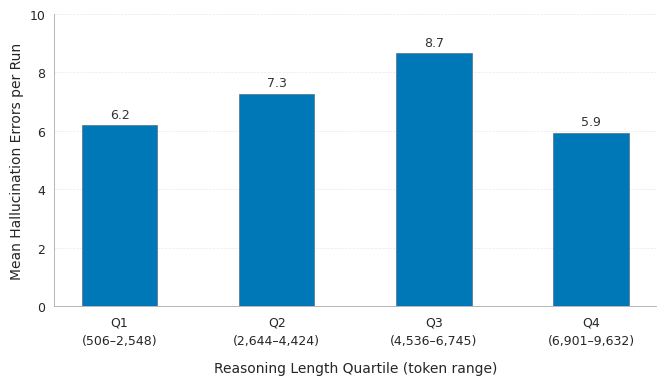

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

means = quartile_stats["Mean_Errors"].to_numpy()
quartiles = quartile_stats["Length_Quartile"].astype(str)
mins = quartile_stats["Min_Tokens"].to_numpy()
maxs = quartile_stats["Max_Tokens"].to_numpy()

x = np.arange(len(quartiles))

fig, ax = plt.subplots(figsize=(7, 4.2))

bars = ax.bar(
    x,
    means,
    width=0.48,
    color="#0077B6",
    edgecolor="#55718C",
    linewidth=0.5,
    zorder=3
)

ax.set_ylim(0, 10)
ax.set_yticks(np.arange(0, 11, 2))

ax.grid(
    axis="y",
    linestyle="--",
    color="#D9D9D9",
    linewidth=0.5,
    alpha=0.6,
    zorder=0
)

ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)


labels = [
    f"{q}\n({mn:,.0f}–{mx:,.0f})"
    for q, mn, mx in zip(quartiles, mins, maxs)
]

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9, linespacing=1.6)

for bar, mean in zip(bars, means):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.15,
        f"{mean:.1f}",
        ha="center",
        va="bottom",
        fontsize=9,
        color="#333333"

    )

ax.set_xlabel(
    "Reasoning Length Quartile (token range)",
    fontsize=10,
    labelpad=10
)
ax.set_ylabel(
    "Mean Hallucination Errors per Run",
    fontsize=10
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#AAAAAA")
ax.spines["bottom"].set_color("#AAAAAA")

ax.spines["left"].set_linewidth(0.6)
ax.spines["bottom"].set_linewidth(0.6)

ax.tick_params(
    axis="both",
    labelsize=9,
    length=3,
    width=0.5
)

plt.tight_layout()

plt.savefig(
    f"{rootDir}/Figures/RQ3_length_quartiles.pdf",
    bbox_inches="tight"
)

plt.savefig(
    f"{rootDir}/Figures/RQ3_length_quartiles.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

#RQ3  thought_tokens
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

# Load dataset
df = pd.read_csv(f"{rootDir}/Result/per_item_ABC_complexity_GT.csv")

# Variables to analyse
error_columns = [
    "A_Total",
    "B_Total",
    "C_Total",
    "Overall_Total"
]

results = []

for col in error_columns:
    data = df[["thought_tokens", col]].copy()

    # Convert to numeric
    data = data.apply(pd.to_numeric, errors="raise")

    # Remove missing pairs
    data = data.dropna()

    if len(data) < 3:
        raise ValueError(f"Insufficient observations for {col}")

    if data["thought_tokens"].nunique() < 2 or data[col].nunique() < 2:
        raise ValueError(f"Constant variable detected for {col}")

    # Spearman rank correlation (two-sided)
    rho, p_value = spearmanr(
        data["thought_tokens"],
        data[col]
    )

    results.append({
        "Dimension": col,
        "N": len(data),
        "Spearman_rho": rho,
        "p_value": p_value,
        "Significant_0.05": p_value < 0.05
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))



    Dimension  N  Spearman_rho  p_value  Significant_0.05
      A_Total 60        0.1921   0.1414             False
      B_Total 60       -0.1150   0.3814             False
      C_Total 60        0.0511   0.6983             False
Overall_Total 60       -0.0109   0.9341             False


In [ ]:
#RQ3 complexity
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

# Load dataset
df = pd.read_csv(f"{rootDir}/Result/per_item_ABC_complexity_GT.csv")

error_columns = {
    "A_Total": "Prompt Faithfulness",
    "B_Total": "Reasoning Quality",
    "C_Total": "Code Faithfulness",
    "Overall_Total": "Overall"
}

results = []

# Convert complexity to numeric
df["Complexity"] = pd.to_numeric(
    df["Complexity"], errors="raise"
)

for col, dimension in error_columns.items():

    data = df[["Complexity", col]].copy()
    data[col] = pd.to_numeric(data[col], errors="raise")

    data = data.dropna()

    if len(data) < 3:
        raise ValueError(f"Insufficient observations for {dimension}")

    if data["Complexity"].nunique() < 2 or data[col].nunique() < 2:
        raise ValueError(f"Constant variable in {dimension}")

    rho, p_value = spearmanr(
        data["Complexity"],
        data[col],
        alternative="two-sided"
    )

    results.append({
        "Dimension": dimension,
        "N": len(data),
        "Spearman_rho": rho,
        "p_value": p_value,
        "Significant_0.05": p_value < 0.05
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))




          Dimension  N  Spearman_rho  p_value  Significant_0.05
Prompt Faithfulness 60       -0.3748   0.0032              True
  Reasoning Quality 60       -0.2085   0.1100             False
  Code Faithfulness 60       -0.1727   0.1871             False
            Overall 60       -0.3254   0.0112              True
